# Tome 15, Appendix G: Hadamard Matrices (Python companion)

Exercises first, solutions at the end. We build finite fields $\mathbb F_q$ from scratch, construct the Paley matrices of Theorems 6.6 and
6.7 for every prime power below $200$, list the orders up to $1000$ that the classical constructions miss, search for Williamson matrices,
and decode the Hadamard code of length $32$. We use `numpy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import itertools, math, time
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(7)

## Exercises

**P7.1 (★★) Finite fields and Paley matrices.** Implement $\mathbb F_{p^k}$ as polynomials modulo an irreducible polynomial of degree $k$. For every odd
prime power $q<200$, build the Paley matrix (Paley I if $q\equiv3\pmod4$, Paley II if $q\equiv1\pmod4$) and check $HH^{\mathsf T}=nI$.

**P7.2 (★) The gaps.** List the multiples of $4$ up to $1000$ that are \emph{not} orders of Kronecker products of $2$, Paley~I orders $q+1$ and Paley~II
orders $2(q+1)$.

**P7.3 (★★) Williamson matrices.** For odd $n\le17$, search for four symmetric circulant $\pm1$ matrices with $A^2+B^2+C^2+D^2=4nI$ (Theorem
6.8). Use the periodic autocorrelations of the first rows, and meet in the middle.

**P7.4 (★) Hadamard codes.** Build the code of Proposition 6.10 from the Sylvester matrix of order $32$ (with the fast transform of
Exercise 6.3). Send random codewords through a channel that flips each bit with probability $p$, decode by the largest correlation, and plot
the word error rate against $p$.

**P7.5 (★) Designs.** From normalised Hadamard matrices of orders $8$ and $12$, extract the designs of Theorem 6.9 and check their
parameters.

## Solutions

### P7.1
**How to find it.** Represent an element of $\mathbb F_{p^k}$ by the integer whose base-$p$ digits are its coefficients. A monic polynomial of degree
$k$ is irreducible if no monic polynomial of degree $1,\dots,\lfloor k/2\rfloor$ divides it. Then $\chi(x)=x^{(q-1)/2}$ (Lemma 6.4).

In [2]:
def is_prime(n): return n > 1 and all(n % d for d in range(2, int(n**0.5) + 1))
def prime_power(q):
    p = next(d for d in range(2, q + 1) if q % d == 0)
    k = 0
    while q % p == 0: q //= p; k += 1
    return (p, k) if q == 1 else None
class GF:
    # F_{p^k}: elements 0..q-1, base-p digits = coefficients (low degree first)
    def __init__(self, p, k):
        self.p, self.k, self.q = p, k, p**k
        self.mod = self.irreducible()
    def digits(self, x): return [(x // self.p**i) % self.p for i in range(self.k)]
    def num(self, c): return sum(int(v) * self.p**i for i, v in enumerate(c))
    def pmod(self, a, m):          # polynomials as lists, low degree first; m monic
        a = a[:]
        while len(a) >= len(m):
            c = a[-1]
            if c:
                for i in range(len(m)):
                    a[len(a) - len(m) + i] = (a[len(a) - len(m) + i] - c * m[i]) % self.p
            a.pop()
        return a
    def irreducible(self):
        p, k = self.p, self.k
        if k == 1: return [0, 1]
        for tail in itertools.product(range(p), repeat=k):
            m = list(tail) + [1]
            ok = True
            for d in range(1, k // 2 + 1):
                for t in itertools.product(range(p), repeat=d):
                    f = list(t) + [1]
                    r = self.pmod(m, f)
                    if not any(r): ok = False; break
                if not ok: break
            if ok: return m
    def add(self, x, y): return self.num([(a + b) % self.p for a, b in zip(self.digits(x), self.digits(y))])
    def neg(self, x): return self.num([(-a) % self.p for a in self.digits(x)])
    def mul(self, x, y):
        a, b = self.digits(x), self.digits(y)
        prod = [0] * (2 * self.k - 1)
        for i, u in enumerate(a):
            for j, v in enumerate(b): prod[i + j] = (prod[i + j] + u * v) % self.p
        r = self.pmod(prod, self.mod) if self.k > 1 else [prod[0] % self.p]
        return self.num(r + [0] * (self.k - len(r)))
    def power(self, x, e):
        r = 1
        while e:
            if e & 1: r = self.mul(r, x)
            x = self.mul(x, x); e >>= 1
        return r
    def chi(self, x):
        if x == 0: return 0
        return 1 if self.power(x, (self.q - 1) // 2) == 1 else -1
def paley(q):
    p, k = prime_power(q); F = GF(p, k)
    ch = [F.chi(x) for x in range(q)]
    Q = np.array([[ch[F.add(x, F.neg(y))] for y in range(q)] for x in range(q)])
    n = q + 1
    S = np.zeros((n, n), dtype=int); S[0, 1:] = 1; S[1:, 1:] = Q
    if q % 4 == 3:
        S[1:, 0] = -1; return np.eye(n, dtype=int) + S
    S[1:, 0] = 1; I = np.eye(n, dtype=int)
    return np.block([[S + I, S - I], [S - I, -S - I]])

t0 = time.time(); res = []
for q in range(3, 200, 2):
    if prime_power(q):
        H = paley(q); n = len(H)
        res.append((q, n, bool((H @ H.T == n * np.eye(n)).all())))
print(len(res), 'prime powers; all Hadamard:', all(r[2] for r in res), ' (%.1f s)' % (time.time() - t0))
print('orders:', sorted({n for _, n, _ in res}))
print('fields that are not prime fields:', [(q, prime_power(q)) for q, _, _ in res if prime_power(q)[1] > 1])

53 prime powers; all Hadamard: True  (1.7 s)
orders: [4, 8, 12, 20, 24, 28, 32, 36, 44, 48, 52, 60, 68, 72, 76, 80, 84, 100, 104, 108, 124, 128, 132, 140, 148, 152, 164, 168, 180, 192, 196, 200, 204, 220, 228, 244, 252, 276, 300, 316, 340, 348, 364, 388, 396]
fields that are not prime fields: [(9, (3, 2)), (25, (5, 2)), (27, (3, 3)), (49, (7, 2)), (81, (3, 4)), (121, (11, 2)), (125, (5, 3)), (169, (13, 2))]


All $53$ odd prime powers below $200$ give Hadamard matrices, including the eight that are not primes ($9,25,27,49,81,121,125,169$), where the field
is not $\mathbb Z/q$ and one really needs polynomial arithmetic. The orders $28=27+1$ and $52=2(25+1)$, for instance, need $\mathbb F_{27}$ and $\mathbb F_{25}$.

### P7.2
**How to find it.** Start from the set of Paley orders and $2$, and close it under products.

In [3]:
N = 1000
base = {2}
for q in range(3, N, 2):
    if prime_power(q):
        base.add(q + 1 if q % 4 == 3 else 2 * (q + 1))
cov = {1} | {b for b in base if b <= N}
grew = True
while grew:
    grew = False
    for a in list(cov):
        for b in list(cov):
            if a * b <= N and a * b not in cov: cov.add(a * b); grew = True
miss = [n for n in range(4, N + 1, 4) if n not in cov]
print(len(miss), 'multiples of 4 up to 1000 missed:', miss)

55 multiples of 4 up to 1000 missed: [92, 116, 156, 172, 184, 188, 232, 236, 260, 268, 292, 324, 356, 372, 376, 404, 412, 428, 436, 452, 472, 476, 508, 520, 532, 536, 584, 596, 604, 612, 652, 668, 712, 716, 732, 756, 764, 772, 808, 836, 852, 856, 872, 876, 892, 904, 932, 940, 944, 952, 956, 964, 980, 988, 996]


The first gap is $92$, the order that waited until 1962, then $116$, $156$, $172$, $184$, ... $55$ gaps in all up to $1000$, among them $428$, $668$, $716$,
$764$ and $892$, the orders that became famous. Most of the gaps were filled long ago by other constructions (Williamson's, Goethals and Seidel's, and
many more); the point here is how quickly the two simplest constructions run out.

### P7.3
**How to find it.** A symmetric circulant matrix is given by $a_0$ and $a_1=a_{n-1}$, ..., $a_h=a_{n-h}$ with $h=\frac{n-1}2$: $2^{h+1}$ choices. For
circulants, $A^2+B^2+C^2+D^2=4nI$ says that the periodic autocorrelations $P_A(s)=\sum_ia_ia_{i+s}$ add up to $0$ for every shift $s\neq0$ (and only
$s\le h$ matter, by symmetry). Store the sums $P_A+P_B$ for all pairs, and look for a pair $(C,D)$ with the opposite sum.

In [4]:
def sym_rows(n):
    h = (n - 1) // 2
    for bits in itertools.product((1, -1), repeat=h + 1):
        yield (bits[0],) + bits[1:] + bits[1:][::-1]
def paf(r):
    r = np.array(r)
    return tuple(int(np.dot(r, np.roll(r, s))) for s in range(1, (len(r) - 1) // 2 + 1))
t0 = time.time()
for n in range(1, 24, 2):
    rows = list(sym_rows(n)); P = {r: paf(r) for r in rows}
    pairs = {}
    for i, a in enumerate(rows):
        for b in rows[i:]:
            pairs.setdefault(tuple(x + y for x, y in zip(P[a], P[b])), (a, b))
    found = next(((pairs[k] + pairs[tuple(-x for x in k)]) for k in pairs if tuple(-x for x in k) in pairs), None)
    M = [np.array([np.roll(r, s) for s in range(n)]) for r in found]
    ok = (sum(X @ X for X in M) == 4 * n * np.eye(n)).all()
    print('n = %2d: Williamson matrices found, check %s, row sums %s  -> Hadamard order %d' % (n, ok, [sum(r) for r in found], 4 * n))
print('%.0f s' % (time.time() - t0))

n =  1: Williamson matrices found, check True, row sums [1, 1, 1, 1]  -> Hadamard order 4
n =  3: Williamson matrices found, check True, row sums [3, -1, -1, -1]  -> Hadamard order 12
n =  5: Williamson matrices found, check True, row sums [1, 1, -3, -3]  -> Hadamard order 20
n =  7: Williamson matrices found, check True, row sums [3, 3, 3, -1]  -> Hadamard order 28
n =  9: Williamson matrices found, check True, row sums [5, 1, 1, -3]  -> Hadamard order 36
n = 11: Williamson matrices found, check True, row sums [3, 3, -1, -5]  -> Hadamard order 44
n = 13: Williamson matrices found, check True, row sums [5, -3, -3, -3]  -> Hadamard order 52
n = 15: Williamson matrices found, check True, row sums [7, -1, 3, -1]  -> Hadamard order 60


n = 17: Williamson matrices found, check True, row sums [5, 5, -3, -3]  -> Hadamard order 68


n = 19: Williamson matrices found, check True, row sums [7, -1, -1, -5]  -> Hadamard order 76


n = 21: Williamson matrices found, check True, row sums [5, 5, 5, -3]  -> Hadamard order 84


n = 23: Williamson matrices found, check True, row sums [7, 3, 3, -5]  -> Hadamard order 92
23 s


Every odd $n\le23$ works, and the search reaches $n=23$, Baumert, Golomb and Hall's order $92$, in well under a minute. The row sums always satisfy
$a^2+b^2+c^2+d^2=4n$ (Exercise 6.7): for $n=23$, $49+9+9+25=92$. In 1962 the same search was a feat. The number of candidate first rows doubles each
time $n$ grows by $2$, and the number of pairs stored in the middle grows four times as fast, so the method runs out of memory and time quickly; and
Williamson matrices do not exist for every odd $n$: Dragomir Djokovi\'c showed by an exhaustive search in 1993 that there are none for $n=35$.

### P7.4
**How to find it.** Codewords: the rows of $\pm S_{32}$, as $\pm1$ vectors. Decoding: compute the $32$ correlations $S_{32}y$ with the fast transform,
take the index $i$ of the largest $|(S_{32}y)_i|$, and the sign.

[(0.0, 0.0), (0.025, 0.0), (0.05, 0.0), (0.075, 0.0), (0.1, 0.0018), (0.125, 0.0073), (0.15, 0.023), (0.175, 0.0455), (0.2, 0.1005), (0.225, 0.1615), (0.25, 0.2695), (0.275, 0.3678), (0.3, 0.4965)]


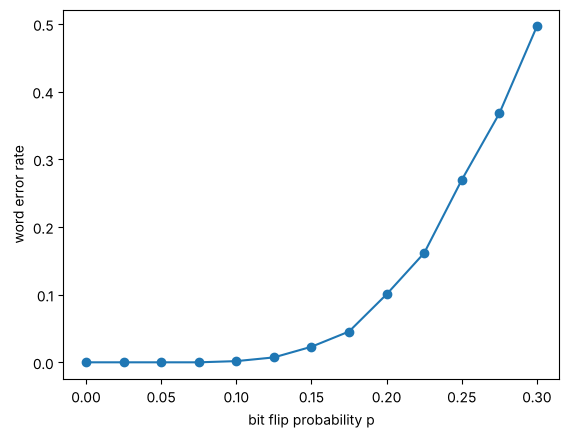

In [5]:
def fwht(x):
    x = x.astype(float).copy(); h = 1
    while h < len(x):
        for i in range(0, len(x), 2 * h):
            a, b = x[i:i + h].copy(), x[i + h:i + 2 * h].copy()
            x[i:i + h], x[i + h:i + 2 * h] = a + b, a - b
        h *= 2
    return x
S32 = np.array([[1]])
for _ in range(5): S32 = np.block([[S32, S32], [S32, -S32]])
y = rng.choice([-1, 1], 32)
assert np.allclose(fwht(y), S32 @ y)
ps = np.linspace(0, 0.3, 13); trials = 4000; wer = []
for p in ps:
    err = 0
    for _ in range(trials):
        i, s = rng.integers(32), rng.choice([-1, 1])
        flips = np.where(rng.random(32) < p, -1, 1)
        c = fwht(s * S32[i] * flips)
        j = np.argmax(np.abs(c))
        err += (j != i) or (np.sign(c[j]) != s)
    wer.append(err / trials)
print([(round(float(p), 3), round(float(w), 4)) for p, w in zip(ps, wer)])
plt.plot(ps, wer, 'o-'); plt.xlabel('bit flip probability p'); plt.ylabel('word error rate'); plt.show()

The code has $64$ words of length $32$ and minimum distance $16$, so it corrects any $7$ errors for certain, and most patterns of $8$ or more. With each
bit flipped independently with probability $p=0.1$ (about $3$ errors per word on average), almost every word is decoded correctly; the error rate
becomes large only when $p$ approaches $0.25$, that is $8$ expected errors. The price is the rate: $6$ bits of information in $32$ transmitted bits.

### P7.5
**How to find it.** Normalise (multiply rows and columns by the sign of their first entry), drop the first row and column, and read the blocks.

In [6]:
def normalise(H):
    H = H * H[:, :1]; return H * H[:1, :]
def design(H):
    H = normalise(H); n = len(H)
    return [frozenset(i for i in range(1, n) if H[i, j] == 1) for j in range(1, n)]
for H in (paley(7), paley(11)):
    B = design(H); v = len(H) - 1
    ks = {len(b) for b in B}
    lam = {sum(1 for b in B if {x, y} <= b) for x, y in itertools.combinations(range(1, v + 1), 2)}
    meet = {len(a & b) for a, b in itertools.combinations(B, 2)}
    print('order %d: v = %d, block sizes %s, pairs in %s blocks, two blocks meet in %s points' % (len(H), v, ks, lam, meet))

order 8: v = 7, block sizes {3}, pairs in {1} blocks, two blocks meet in {1} points
order 12: v = 11, block sizes {5}, pairs in {2} blocks, two blocks meet in {2} points


Order $8$ gives the Fano plane $2$-$(7,3,1)$ and order $12$ the biplane $2$-$(11,5,2)$, and in both cases two blocks meet in exactly $\lambda$ points,
as Exercise 6.10 predicts for symmetric designs. (Here the order-$8$ matrix is Paley~I for $q=7$, not Sylvester's, which gives another,
isomorphic, Fano plane: there is only one Fano plane up to relabelling.)